In [18]:
import pandas as pd 
from sklearn.model_selection import train_test_split, learning_curve, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline 
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# Model Selection 

In [7]:
data = pd.read_csv('housing/housing.csv')
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [9]:
data.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [10]:
X = data[['housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity']]
y = data['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = ['housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
cat_cols = ['ocean_proximity']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

column_transform = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

models = {
    'LinearRegression': LinearRegression(),
    'DecisionTree': DecisionTreeRegressor(max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_split=10, min_samples_leaf=5, random_state=42, n_jobs=-1)
}

for name, model in models.items():
    full_pipeline = Pipeline([
        ('preprocessing', column_transform),
        ('model', model)
    ])

    scores = cross_val_score(full_pipeline, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    rmse_cv = np.sqrt(-scores).mean()

    full_pipeline.fit(X_train, y_train)

    y_pred = full_pipeline.predict(X_test)

    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))

    print(f"{name}")
    print('CV RMSE: ', rmse_cv)
    print('Test RMSE:', rmse_test)

LinearRegression
CV RMSE:  69764.3765870032
Test RMSE: 70925.36950193123
DecisionTree
CV RMSE:  71606.16634640643
Test RMSE: 72290.28822657203
RandomForest
CV RMSE:  62619.09849994663
Test RMSE: 64349.01259493196


In [11]:
# Hyperparameter Tuning

pipe_tune = Pipeline([
    ('preprocessing', column_transform),
    ('classifier', RandomForestRegressor())
    ])

search_space = [
    {
        "classifier": [LinearRegression()]
    },
    {
        "classifier": [DecisionTreeRegressor()],
        'classifier__max_depth': [3, 5, 10],
        "classifier__min_samples_split": [2, 10],
        "classifier__min_samples_leaf": [1, 5]
    },
    {
        'classifier': [RandomForestRegressor()],
        "classifier__n_estimators": [50, 100],
        "classifier__max_depth": [5, 10],
        "classifier__min_samples_split": [2, 10],
        "classifier__min_samples_leaf": [1, 5]
    }
]


grid_search = GridSearchCV(pipe_tune, search_space, cv=5, scoring='neg_mean_squared_error', verbose=0)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['housing_median_age',
                                                                          'total_rooms',
                                                                          'total_bedrooms',
                                                                          'population',
                                                                          'households',
                                                                          'median_income']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['ocean_proximit...
                         {'classifier': [DecisionTreeRegressor()],
                          'classifier__max_depth': [3, 5, 10],
                          'classifier__min_samples_leaf': [1, 5],
                          'classifier__min_samples_split': [2, 10]},
                         {'classifier': [RandomForestRegressor()],
                          'classifier__max_depth': [5, 10],
                          'classifier__min_samples_leaf': [1, 5],
                          'classifier__min_samples_split': [2, 10],
                          'classifier__n_estimators': [50, 100]}],
             scoring='neg_mean_squared_error')

In [12]:
best_model = grid_search.best_estimator_
print('Best Params:', grid_search.best_params_)

y_pred = best_model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print('Test RMSE:', rmse)

Best Params: {'classifier': RandomForestRegressor(), 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 100}
Test RMSE: 64256.86302096866


# Overfitting and Underfitting Check

In [14]:
y_train_pred = best_model.predict(X_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))

y_test_pred = best_model.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

cv_rmse = np.sqrt(-grid_search.best_score_)

print('Best CV RMSE:',cv_rmse)
print('Train RMSE:', rmse_train)
print('Test RMSE:', rmse_test)

Best CV RMSE: 62610.819864118974
Train RMSE: 53302.931999063
Test RMSE: 64256.86302096866


In [16]:
train_sizes, train_scores, val_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring='neg_mean_squared_error'
)

train_rmse = np.sqrt(-train_scores.mean(axis=1))
val_rmse = np.sqrt(-val_scores.mean(axis=1))

In [17]:
print('Train RMSE:', train_rmse)
print('Val RMSE:', val_rmse)

Train RMSE: [47042.82410367 49643.52295337 50702.34959435 51559.02635486
 52489.10222702]
Val RMSE: [67224.5935972  64157.37527813 63397.29703338 63027.31865922
 62620.52345846]


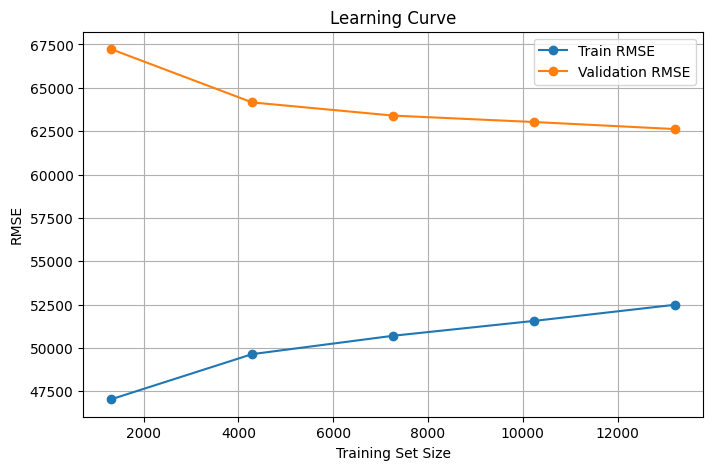

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(train_sizes, train_rmse, marker='o', label='Train RMSE')
plt.plot(train_sizes, val_rmse, marker='o', label='Validation RMSE')

plt.xlabel('Training Set Size')
plt.ylabel('RMSE')
plt.title('Learning Curve')

plt.legend()
plt.grid(True)
plt.show()